In [ ]:
!pip install git+https://github.com/EvgenyGorelik/multiview_incabin_dataset.git

In [1]:
from ndf_dataset import NDFDataset
import os

NDF_DATA_DIR = os.environ.get("NDF_DATA_DIR", "/run/media/evgeny/T7/ndf/beintelli_v1")  # Set this environment variable to your dataset path 

ds = NDFDataset(NDF_DATA_DIR)

## Recording scenes

`ds.scenes` groups all available camera streams, LiDAR scans, and 3D box samples
by recording using `scenes.json`. Images are loaded on demand. Each scene also
shares the dataset calibration and static map. Scene sampling never selects a
sensor frame from a different recording.


In [2]:
for scene_name, scene in ds.scenes.items():
    image_count = sum(len(camera.images) for group in scene.cameras.values()
                      for camera in group.values())
    print(f"{scene_name}: {len(scene)} samples, {image_count} images, "
          f"{len(scene.lidar_scans)} LiDAR scans")

if ds.scenes:
    scene = next(iter(ds.scenes.values()))
    if len(scene):
        files = scene.get_sample_files(scene.timestamps[0])
        print(f"First sample: scene={files.scene_id}, timestamp={files.timestamp}")
        # Use scene[0] to load the sample's boxes, images and LiDAR points.
else:
    print('No scenes.json available; samples can still be accessed through ds.')


rosbag2_2026_05_21-09_10_44: 1926 samples, 19995 images, 1926 LiDAR scans
rosbag2_2026_05_21-09_15_06: 1392 samples, 14239 images, 1392 LiDAR scans
rosbag2_2026_05_21-09_21_59: 1203 samples, 12287 images, 1203 LiDAR scans
rosbag2_2026_05_21-09_24_35: 772 samples, 7876 images, 772 LiDAR scans
rosbag2_2026_05_21-09_27_19: 302 samples, 2916 images, 302 LiDAR scans
rosbag2_2026_05_21-09_28_32: 905 samples, 9300 images, 905 LiDAR scans
rosbag2_2026_05_21-09_32_27: 740 samples, 7641 images, 740 LiDAR scans
rosbag2_2026_05_21-09_34_14: 422 samples, 4175 images, 422 LiDAR scans
rosbag2_2026_05_21-09_36_03: 557 samples, 5411 images, 557 LiDAR scans
rosbag2_2026_05_21-09_37_12: 537 samples, 5461 images, 537 LiDAR scans
rosbag2_2026_05_21-09_40_56: 1278 samples, 12891 images, 1278 LiDAR scans
First sample: scene=rosbag2_2026_05_21-09_10_44, timestamp=1779354644546117587


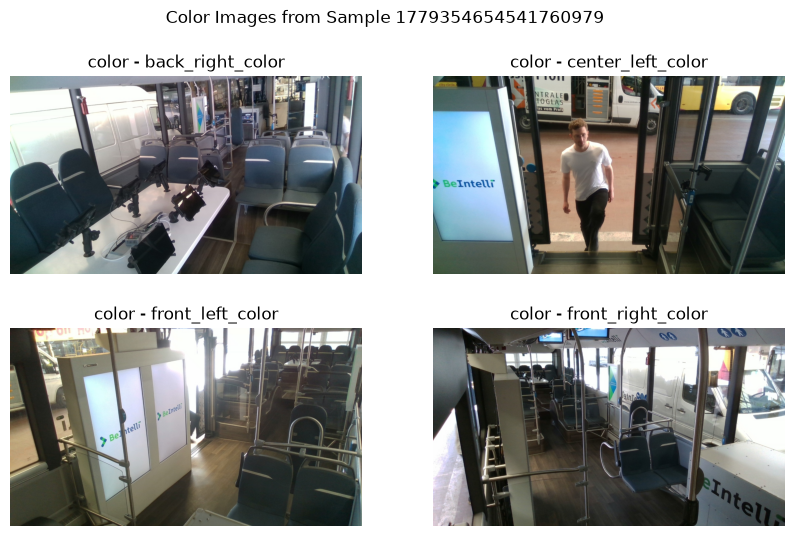

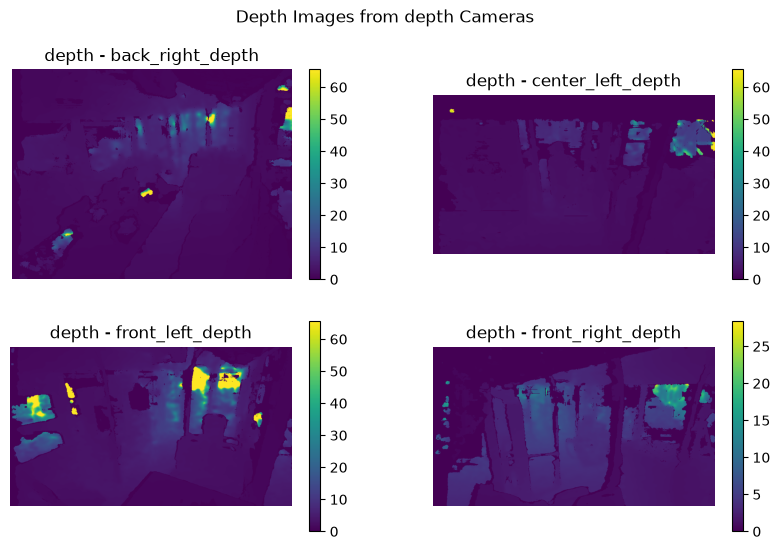

In [3]:
import matplotlib.pyplot as plt

sample = ds[100]

cam_type = 'color'
plt.figure(figsize=(10, 6))
plt.suptitle(f"{cam_type.capitalize()} Images from Sample {sample.timestamp}")
for cam_name in ds.cameras.get(cam_type, {}).keys():
    img = sample.cameras[cam_type][cam_name].image
    if img is None:
        continue
    plt.subplot(2, 2, list(ds.cameras.get(cam_type, {}).keys()).index(cam_name) + 1)
    plt.imshow(img)
    plt.title(f"{cam_type} - {cam_name}")
    plt.axis('off')
plt.show()

cam_type = 'depth'
plt.figure(figsize=(10, 6))
plt.suptitle(f"Depth Images from {cam_type} Cameras")
for cam_name in ds.cameras.get(cam_type, {}).keys():
    img = sample.cameras[cam_type][cam_name].image
    if img is None:
        continue
    plt.subplot(2, 2, list(ds.cameras.get(cam_type, {}).keys()).index(cam_name) + 1)
    plt.imshow(img / 1000)
    plt.colorbar()
    plt.title(f"{cam_type} - {cam_name}")
    plt.axis('off')
plt.show()

In [4]:
# Inspect the metadata attached to each 3D bounding box.
print(f"Sample timestamp: {sample.timestamp}")
for bbox in sample.bboxes_3d:
    print(
        f"Object {bbox.obj_id}: {bbox.bbox_label}, "
        f"attribute={bbox.attr}, action={bbox.action}, "
        f"velocity={bbox.velocity.tolist() if bbox.velocity is not None else None}"
    )


Sample timestamp: 1779354654541760979
Object 1: human, attribute=enter vehicle, action=none, velocity=[-0.18262911869969645, 0.006741572449786126, 0.05336218980757512]


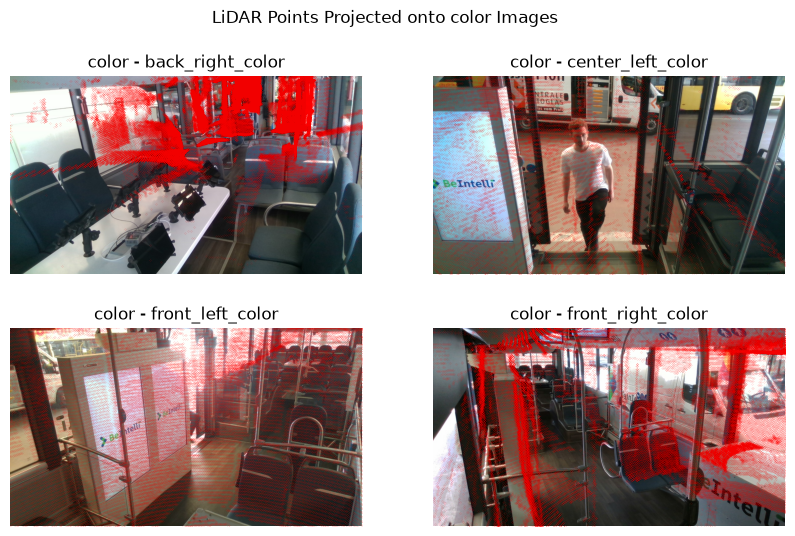

In [5]:
from ndf_dataset.transforms import project_points

cam_type = 'color'
plt.figure(figsize=(10, 6))
plt.suptitle(f"LiDAR Points Projected onto {cam_type} Images")
for cam_name in ds.cameras.get(cam_type, {}).keys():
    if sample.lidar is None:
        continue
    img = sample.cameras[cam_type][cam_name].image
    lidar_points = sample.lidar.points
    cam_int = ds.cameras[cam_type][cam_name].intrinsics
    T_lidar_to_cam = ds.get_transform(source_frame=ds.lidar_frame, target_frame=ds.cameras[cam_type][cam_name].frame_id)
    projected_points = project_points(lidar_points, cam_int, T_lidar_to_cam)
    if img is None:
        continue
    plt.subplot(2, 2, list(ds.cameras.get(cam_type, {}).keys()).index(cam_name) + 1)
    plt.scatter(projected_points[:, 0], projected_points[:, 1], s=0.01, alpha=0.5, c='red')
    plt.imshow(img)
    plt.title(f"{cam_type} - {cam_name}")
    plt.axis('off')
plt.show()


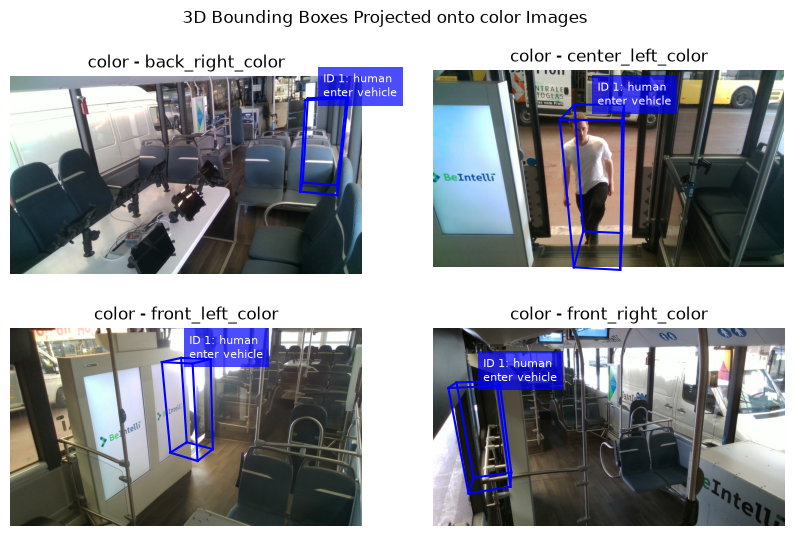

In [6]:
cam_type = 'color'

edge_connections = [(0, 1), (1, 2), (2, 3), (3, 0), (4, 5), (5, 6), (6, 7), (7, 4), (0, 4), (1, 5), (2, 6), (3, 7)]

plt.figure(figsize=(10, 6))
plt.suptitle(f"3D Bounding Boxes Projected onto {cam_type} Images")
for cam_name in ds.cameras.get(cam_type, {}).keys():
    img = sample.cameras[cam_type][cam_name].image
    if img is None:
        continue
    plt.subplot(2, 2, list(ds.cameras.get(cam_type, {}).keys()).index(cam_name) + 1)
    plt.imshow(img)
    for bbox in sample.bboxes_3d:
        bbox_cam = project_points(bbox.bbox_corners, ds.cameras[cam_type][cam_name].intrinsics, ds.get_transform(source_frame='base_link', target_frame=ds.cameras[cam_type][cam_name].frame_id))
        label = f"ID {bbox.obj_id}: {bbox.bbox_label}"
        if bbox.attr:
            label += f"\n{bbox.attr}"
        if bbox.action and bbox.action != "none":
            label += f"\nAction: {bbox.action}"
        plt.text(
            bbox_cam[:, 0].mean(), bbox_cam[:, 1].min(), label,
            color='white', fontsize=8,
            bbox=dict(facecolor='blue', alpha=0.7, edgecolor='none'),
        )
        for start, end in edge_connections:
            plt.plot([bbox_cam[start, 0], bbox_cam[end, 0]], [bbox_cam[start, 1], bbox_cam[end, 1]], c='blue')
    plt.title(f"{cam_type} - {cam_name}")
    plt.axis('off')
plt.show()


## Depth projected into RGB

Depth pixels are back-projected using the depth camera intrinsics, transformed
into the paired RGB camera frame, and projected using the RGB intrinsics.
`DEPTH_SCALE = 0.001` converts the dataset's millimetres to metres; change it
if your depth images use other units. Camera pairs are matched by their names
(e.g. `front_left_depth` and `front_left_color`); edit `camera_pairs` if needed.
The overlay keeps the closest projected point per RGB pixel, excludes invalid
depths and points behind the camera, and colors points by RGB-camera depth.
The sensor timestamps shown in the titles can differ because frames are
associated by nearest timestamp.


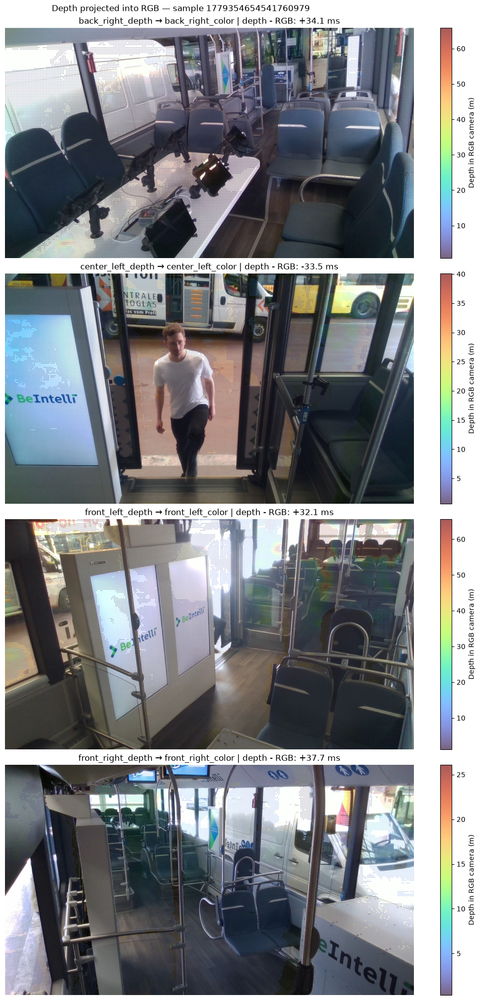

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from ndf_dataset.geometry.transforms import transform_pointcloud

DEPTH_SCALE = 0.001  # Stored depth units -> metres.
DEPTH_STRIDE = 2    # Set to 1 to project every depth pixel.


def visible_rgb_points(points, transform, rgb_frame):
    """Project XYZ points, retaining the nearest point per visible RGB pixel."""
    camera_points = transform_pointcloud(points, transform)
    valid = np.isfinite(camera_points).all(axis=1) & (camera_points[:, 2] > 0)
    camera_points = camera_points[valid]
    projected = camera_points @ rgb_frame.camera.intrinsics.T
    uv = projected[:, :2] / projected[:, 2:3]
    height, width = rgb_frame.image.shape[:2]
    visible = (np.isfinite(uv).all(axis=1)
               & (uv[:, 0] >= 0) & (uv[:, 0] < width)
               & (uv[:, 1] >= 0) & (uv[:, 1] < height))
    uv = uv[visible]
    depth = camera_points[visible, 2]
    pixels = np.floor(uv).astype(np.int64)
    pixel_ids = pixels[:, 1] * width + pixels[:, 0]
    order = np.lexsort((depth, pixel_ids))
    _, first = np.unique(pixel_ids[order], return_index=True)
    nearest = order[first]
    return uv[nearest], depth[nearest]


def depth_to_points(depth_frame, scale=DEPTH_SCALE, stride=DEPTH_STRIDE):
    """Back-project valid depth pixels into their optical camera frame."""
    depth = depth_frame.image[::stride, ::stride].astype(np.float64) * scale
    rows, cols = np.indices(depth.shape)
    pixels = np.stack((cols * stride, rows * stride, np.ones_like(cols)), axis=-1)
    valid = np.isfinite(depth) & (depth > 0)
    rays = pixels[valid] @ np.linalg.inv(depth_frame.camera.intrinsics).T
    return rays * depth[valid, None]


rgb_frames = sample.cameras.get('color', {})
depth_frames = sample.cameras.get('depth', {})
camera_pairs = {}
for rgb_name in rgb_frames:
    depth_name = (rgb_name[:-6] + '_depth' if rgb_name.endswith('_color') else rgb_name)
    if depth_name in depth_frames:
        camera_pairs[rgb_name] = depth_name

if not camera_pairs:
    print('No matching RGB/depth cameras. Set camera_pairs to {rgb_name: depth_name}.')
else:
    fig, axes = plt.subplots(len(camera_pairs), 1, figsize=(12, 5 * len(camera_pairs)), squeeze=False, layout="constrained")
    fig.suptitle(f'Depth projected into RGB — sample {sample.timestamp}')
    for ax, (rgb_name, depth_name) in zip(axes[:, 0], camera_pairs.items()):
        rgb = rgb_frames[rgb_name]
        depth_frame = depth_frames[depth_name]
        ax.axis('off')
        if rgb.image is None or depth_frame.image is None:
            ax.set_title(f'{rgb_name}: RGB or depth image unavailable')
            continue
        ax.imshow(rgb.image)
        transform = ds.get_transform(depth_frame.camera.frame_id, rgb.camera.frame_id)
        if transform is None:
            ax.set_title(f'{rgb_name}: depth-to-RGB transform unavailable')
            continue
        points = depth_to_points(depth_frame)
        uv, distances = visible_rgb_points(points, transform, rgb)
        if distances.size:
            scatter = ax.scatter(uv[:, 0], uv[:, 1], c=distances, s=1,
                                 cmap='turbo', alpha=0.65, linewidths=0)
            fig.colorbar(scatter, ax=ax, label='Depth in RGB camera (m)')
        ax.set_xlim(-0.5, rgb.image.shape[1] - 0.5)
        ax.set_ylim(rgb.image.shape[0] - 0.5, -0.5)
        offset_ms = (depth_frame.timestamp - rgb.timestamp) / 1e6
        ax.set_title(f'{depth_name} → {rgb_name} | depth - RGB: {offset_ms:+.1f} ms')
    plt.show()


## Static point cloud map overlaid on RGB

This example assumes `dense_cleaned.ply` uses `base_link` coordinates. Set
`MAP_FRAME` to the map's actual calibrated frame if different. A world-frame
map needs a world-to-camera transform for this sample; static sensor calibration
alone does not provide vehicle localization.

The map is sampled for interactive plotting, transformed into each RGB camera,
and colored by camera depth. Only points in front of the camera and within the
image are drawn, keeping the nearest map point per RGB pixel. The static map
does not account for moving people or other foreground objects in the RGB image.


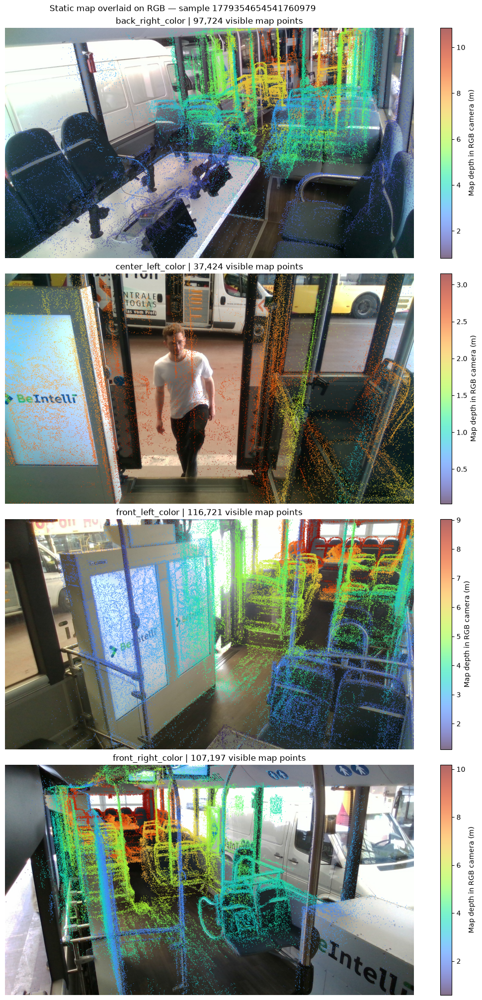

In [8]:
MAP_FRAME = 'base_link'
MAX_MAP_POINTS = 200_000  # Increase for a denser overlay, or use None for all points.

if ds.pcd_map is None:
    print('No map available at map/dense_cleaned.ply.')
elif not rgb_frames:
    print('No RGB cameras available.')
else:
    map_points = ds.pcd_map
    if MAX_MAP_POINTS is not None and len(map_points) > MAX_MAP_POINTS:
        indices = np.linspace(0, len(map_points) - 1, MAX_MAP_POINTS, dtype=np.int64)
        map_points = map_points[indices]
    fig, axes = plt.subplots(len(rgb_frames), 1, figsize=(12, 5 * len(rgb_frames)), squeeze=False, layout="constrained")
    fig.suptitle(f'Static map overlaid on RGB — sample {sample.timestamp}')
    for ax, (rgb_name, rgb) in zip(axes[:, 0], rgb_frames.items()):
        ax.axis('off')
        if rgb.image is None:
            ax.set_title(f'{rgb_name}: RGB image unavailable')
            continue
        ax.imshow(rgb.image)
        transform = ds.get_transform(MAP_FRAME, rgb.camera.frame_id)
        if transform is None:
            ax.set_title(f'{rgb_name}: {MAP_FRAME}-to-RGB transform unavailable')
            continue
        uv, distances = visible_rgb_points(map_points, transform, rgb)
        if distances.size:
            scatter = ax.scatter(uv[:, 0], uv[:, 1], c=distances, s=1,
                                 cmap='turbo', alpha=0.6, linewidths=0)
            fig.colorbar(scatter, ax=ax, label='Map depth in RGB camera (m)')
        ax.set_xlim(-0.5, rgb.image.shape[1] - 0.5)
        ax.set_ylim(rgb.image.shape[0] - 0.5, -0.5)
        ax.set_title(f'{rgb_name} | {len(distances):,} visible map points')
    plt.show()
